# Exploring a knowledge graph built by a small LLM

This notebook looks at the **full LightRAG graph** from the Knowledge_Graphs project. **Qwen2.5-7B** built it by
reading all **2,917 passages** of 373 Wikipedia mechanics articles. For each passage it extracted entities
(with a type and a description) and the relations between them. Every entity and relation remembers which
passages it came from.

1. **Snapshots:** what the graph looks like, from the whole thing down to single facts.
2. **Network-science measures:** degree distribution, clustering, path lengths, assortativity, cores,
   centrality, communities, robustness. Each is compared with a random graph of the same size where that helps.
3. **Knowledge-graph measures:** types and schema, relation vocabulary, provenance, redundancy, and
   completeness. These follow the quality dimensions used in the KG literature.
4. **Takeaways**, computed from the numbers above.

Data: `data/` in this repository. Interactive viewer: `docs/index.html` (the live demo).

In [1]:
import json, re, random, math, collections
import numpy as np, networkx as nx, igraph as ig, matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import Markdown, display
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
D = "../data"   # repo data folder (relative to notebooks/)
SEP = "<SEP>"
G = nx.read_graphml(f"{D}/graphs/lightrag_main/graph_chunk_entity_relation.graphml")
def camel(s):  return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", s)
from urllib.parse import unquote
def first(s, n=160):
    s = unquote((s or "").split(SEP)[0]).replace("_", " ").strip()   # some descriptions come back URL-encoded
    return s if len(s) <= n else s[:n - 1] + "…"
def sources(a): return [c for c in (a.get("file_path") or "").split(SEP) if c]
R = {}   # numbers reused in the takeaways
R["n"], R["m"] = G.number_of_nodes(), G.number_of_edges()
print(f"{R['n']:,} entities, {R['m']:,} relations")

43,999 entities, 29,551 relations


### What one entity and one relation look like
Each **node** is an entity with a type, a description (descriptions merged from every passage that mentions
it, joined by `<SEP>`), and its source passages. Each **edge** is a relation with keywords (the relation
"label"), a description, a weight, and its source passages.

In [2]:
hub = max(G.degree, key=lambda x: x[1])[0]
a = G.nodes[hub]
print("ENTITY:", hub, "| type:", a.get("entity_type"), "| degree:", G.degree(hub))
print("  description:", first(a.get("description"), 300))
print("  mentioned in", len(sources(a)), "passages, e.g.", sources(a)[:5])
u, v, e = next(iter(G.edges(hub, data=True)))
print("\nRELATION:", u, "--", e.get("keywords"), "--", v)
print("  description:", first(e.get("description"), 300))
print("  sources:", sources(e))

ENTITY: GeneralRelativity | type: concept | degree: 229
  description: General relativity is a fundamental theory in physics formulated by Albert Einstein between 1907 and 1915. It describes gravity as the curvature of spacetime caused by mass and energy, extending the principles of special relativity to non-inertial frames using Riemannian geometry. This theory is of…
  mentioned in 76 passages, e.g. ['19559_002', '2679845_001', '23912155_006', '23912155_003', '24669_006']

RELATION: GeneralRelativity -- Attribution,Develop,Developed,Proposed,developed -- AlbertEinstein
  description: Albert Einstein developed the theory of general relativity between 1907 and 1915.
  sources: ['30001_000', '12024_002', '12024_012', '12024_028', '1789646_000', '1784313_015']


## 1. Snapshots

### The whole graph
Below is the largest connected component, laid out by a force-directed algorithm (DrL) so that linked entities
sit together. Colours are communities found by Louvain modularity optimisation (Part 2). Dense coloured
regions are topics. Entities with no links at all are not drawn; there are many of them (Part 2).

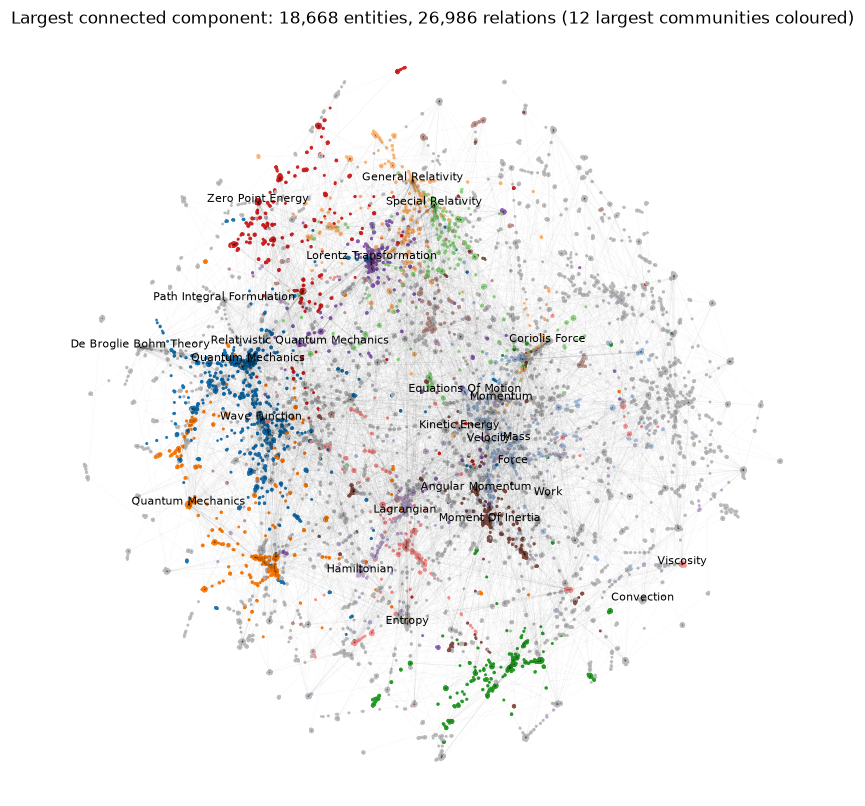

In [3]:
gcc_nodes = max(nx.connected_components(G), key=len)
GC = G.subgraph(gcc_nodes).copy()
names = list(GC.nodes()); idx = {n: i for i, n in enumerate(names)}
h = ig.Graph(n=len(names), edges=[(idx[u], idx[v]) for u, v in GC.edges()])
pos = np.array(h.layout_drl().coords)
comm = h.community_multilevel()                 # Louvain
memb = np.array(comm.membership)
big = [c for c, _ in collections.Counter(memb).most_common(12)]
cmap = plt.get_cmap("tab20")
col = [cmap(big.index(c) % 20) if c in big else (0.75, 0.75, 0.75, 1) for c in memb]
fig, ax = plt.subplots(figsize=(9, 9))
segs = [(pos[idx[u]], pos[idx[v]]) for u, v in GC.edges()]
ax.add_collection(LineCollection(segs, colors=(0, 0, 0, 0.04), linewidths=0.3))
deg = np.array([GC.degree(n) for n in names])
ax.scatter(pos[:, 0], pos[:, 1], s=1 + 2 * np.sqrt(deg), c=col, linewidths=0)
for i in np.argsort(-deg)[:25]:
    ax.annotate(camel(names[i]), pos[i], fontsize=7, ha="center")
ax.set_title(f"Largest connected component: {len(names):,} entities, {GC.number_of_edges():,} relations "
             f"(12 largest communities coloured)"); ax.axis("off"); plt.show()

### A hub and its neighbours, with relation labels
The most connected entity and its 30 best-connected neighbours. Edge labels are the relation keywords the
LLM wrote.

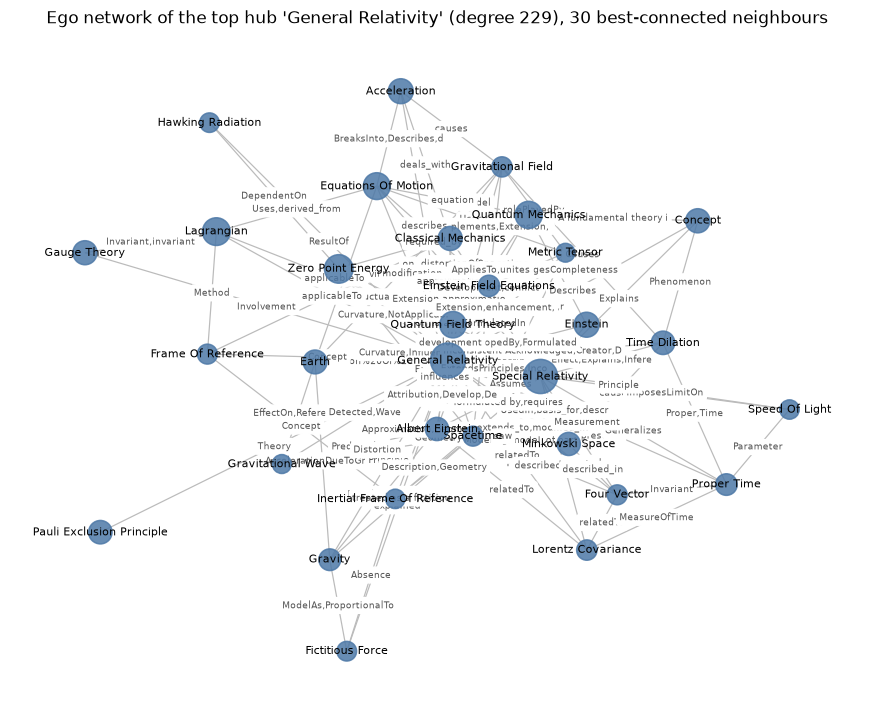

In [4]:
def draw(sub, title, path=None, k=30, seed=1, size=(10, 8)):
    p = nx.spring_layout(sub, seed=seed, k=1.2 / math.sqrt(max(sub.number_of_nodes(), 1)))
    fig, ax = plt.subplots(figsize=size)
    pe = set(zip(path, path[1:])) | set(zip(path[1:], path)) if path else set()
    nx.draw_networkx_edges(sub, p, ax=ax, edge_color=["crimson" if (u, v) in pe else "#bbb" for u, v in sub.edges()],
                           width=[2.5 if (u, v) in pe else 0.8 for u, v in sub.edges()])
    nx.draw_networkx_nodes(sub, p, ax=ax, node_size=[60 + 6 * G.degree(n) ** 0.8 for n in sub],
                           node_color=["crimson" if path and n in path else "#4e79a7" for n in sub], alpha=0.85)
    nx.draw_networkx_labels(sub, p, {n: camel(n) for n in sub}, font_size=7, ax=ax)
    el = {(u, v): (d.get("keywords") or "")[:22] for u, v, d in sub.edges(data=True)}
    nx.draw_networkx_edge_labels(sub, p, el, font_size=6, font_color="#555", ax=ax, rotate=False)
    ax.set_title(title); ax.axis("off"); plt.show()

nb = sorted(G.neighbors(hub), key=G.degree, reverse=True)[:30]
draw(G.subgraph([hub] + nb), f"Ego network of the top hub '{camel(hub)}' (degree {G.degree(hub)}), 30 best-connected neighbours")

### A multi-step path, with provenance
Graph RAG hopes for chains like this: a question about one entity is answered by following relations to
another. The shortest path between two physicists is shown below, with every fact's source passage. Each
hop is a fact a step-by-step reasoner could cite.

Galileo Galilei → Niels Bohr: 3 hops

  Galileo Galilei —[demonstrated]→ Gravity
      Galileo demonstrated that the acceleration due to gravity is independent of the mass of the object.  (source: 10902_002)
  Gravity —[DevelopTheory]→ Albert Einstein
      Albert Einstein developed a theory where gravity is treated as a fictitious force.  (source: 1082841_006)
  Albert Einstein —[explained,replied]→ Niels Bohr
      Einstein used Bohr's model to explain the photoelectric effect.  (source: 25202_017, 211602_001)


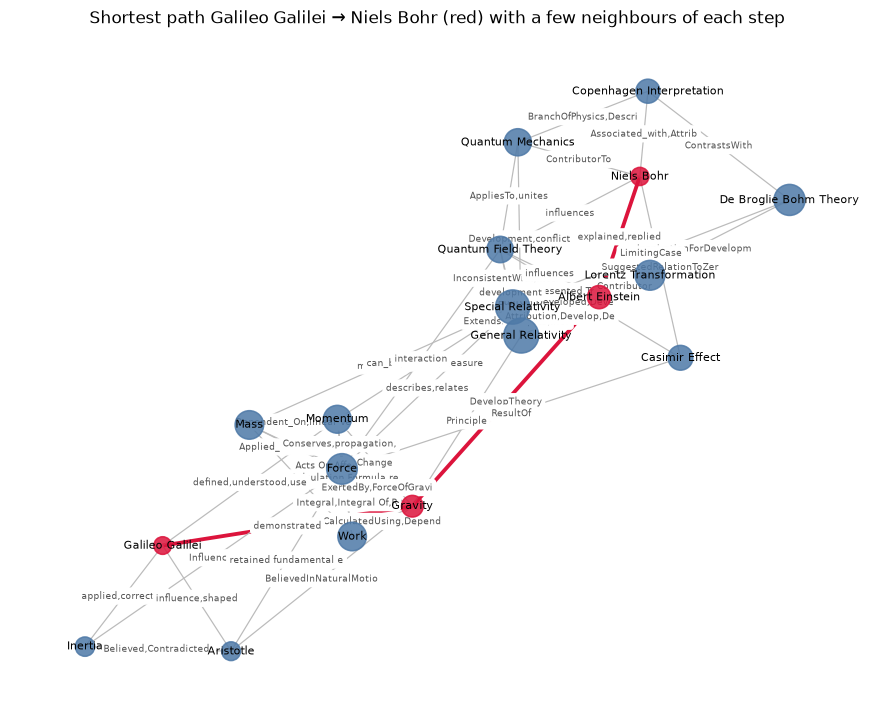

In [5]:
def norm(s):
    s = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", s.strip()); s = re.sub(r"[-–—/_]", " ", s.lower())
    return " ".join(re.sub(r"[^\w\s]", "", s).split())
NORM = {n: norm(n) for n in G}
def find(q):
    q = norm(q); exact = [n for n in G if NORM[n] == q]
    cands = exact or [n for n in G if q in NORM[n]]
    return max(cands, key=G.degree) if cands else None
# the first pair of physicists at least 3 hops apart (a 1-hop pair shows nothing)
for a_, b_ in [("Galileo Galilei", "Niels Bohr"), ("Johannes Kepler", "Paul Dirac"), ("Isaac Newton", "Werner Heisenberg"),
               ("Galileo Galilei", "Erwin Schrödinger"), ("Isaac Newton", "Max Planck"), ("Isaac Newton", "Albert Einstein")]:
    s, t = find(a_), find(b_)
    if s and t and nx.has_path(G, s, t) and nx.shortest_path_length(G, s, t) >= 3:
        break
path = nx.shortest_path(G, s, t)
print(f"{camel(s)} → {camel(t)}: {len(path) - 1} hops\n")
for u, v in zip(path, path[1:]):
    d = G.edges[u, v]
    print(f"  {camel(u)} —[{d.get('keywords')}]→ {camel(v)}\n      {first(d.get('description'), 140)}  (source: {', '.join(sources(d))})")
around = set(path)
for n in path:
    around |= set(sorted(G.neighbors(n), key=G.degree, reverse=True)[:4])
draw(G.subgraph(around), f"Shortest path {camel(s)} → {camel(t)} (red) with a few neighbours of each step", path=path)

### A typical KG query and response

**(a) A structured query.** In a graph database you ask for a *pattern*. The Cypher query
`MATCH (p:person)-[r]-(x) WHERE p.name CONTAINS 'Bohm' RETURN p, r, x` reads "every relation touching an entity
named Bohm". The response is a set of facts, each with its source passage:

In [6]:
q_ent = find("David Bohm") or find("Bohm")
print(f"QUERY: facts about '{camel(q_ent)}'  (type {G.nodes[q_ent].get('entity_type')}, {G.degree(q_ent)} relations)\n")
for _, x, d in sorted(G.edges(q_ent, data=True), key=lambda e: -G.degree(e[1]))[:10]:
    print(f"  {camel(q_ent)} —[{d.get('keywords')}]→ {camel(x)}   ({', '.join(sources(d))})\n      {first(d.get('description'), 130)}")

QUERY: facts about 'David Bohm'  (type person, 10 relations)

  David Bohm —[Context,variant]→ Einstein–Podolsky–Rosen paradox   (10296_005, 10296_004)
      David Bohm's hidden-variable theory provided a context for understanding the EPR paradox.
  David Bohm —[proposed]→ Bohm's hidden-variable theory   (211602_005)
      David Bohm proposed Bohm's hidden-variable theory.
  David Bohm —[author_of]→ Peter R. Holland   (8057418_011)
      Wrote a book on the quantum theory of motion based on the de Broglie-Bohm causal interpretation of quantum mechanics.
  David Bohm —[FollowedBy]→ Louis de Broglie   (8057418_000)
      David Bohm introduced the quantum potential after Louis de Broglie postulated the pilot wave theory.
  David Bohm —[co-author]→ F. David Peat   (8057418_011)
      Co-authored a book on science, order, and creativity with F. David Peat.
  David Bohm —[published_by]→ Routledge   (8057418_011)
      Published a book titled "Science, Order and Creativity" through this organ

**(b) A graph-RAG question, end to end.** Users ask questions in natural language, not patterns. A graph-RAG
system (1) **links** the question to entities, (2) **retrieves** the facts around them, (3) hands those facts
and their source passages to the **LLM**, which (4) **answers and cites**. Below is a real eval question, chosen
automatically as one where the graph links a question entity directly to the gold answer. Step 1 here uses
simple name matching; LightRAG uses keyword extraction by the LLM plus embedding search. The answer at the
end is the 7B model's actual answer from the experiment runs.

In [7]:
import os
ev = [json.loads(l) for l in open(f"{D}/eval/physics_v1_mech/eval_v1.jsonl")]
def linked(question):
    toks = norm(question).split()
    grams = {" ".join(toks[i:i + n]) for n in (4, 3, 2, 1) for i in range(len(toks) - n + 1)}
    return [n for n in G if NORM[n] in grams and len(NORM[n]) > 3 and G.degree(n) > 0]
pick = None
for q in ev:
    if q["type"] != "single":
        continue
    gold = [n for n in G if NORM[n] == norm(q["answer"])]
    ents = linked(q["question"])
    if gold and any(G.has_edge(e, g) for e in ents for g in gold):
        pick = (q, ents, gold); break
q, ents, gold = pick
print("QUESTION:", q["question"])
print("GOLD ANSWER:", q["answer"], "   gold passage:", [s["chunk_id"] for s in q["support"]])
print("\n1. LINK  — entities named in the question:", [camel(e) for e in ents])
print("\n2. RETRIEVE — facts around them, ranked by word overlap with the question (top 8):")
qw = set(norm(q["question"]).split()) - {"what", "the", "of", "a", "on", "does", "is", "in", "to"}
def score(e, x):
    d = G.edges[e, x]
    return len(qw & set(norm(f"{e} {x} {d.get('keywords', '')} {first(d.get('description'), 400)}").split()))
facts = sorted({(e, x) for e in ents for x in G.neighbors(e)}, key=lambda p: -score(*p))[:8]
for e, x in facts:
    d = G.edges[e, x]
    mark = "   <-- answer entity" if x in gold else ""
    print(f"   {camel(e)} —[{d.get('keywords')}]→ {camel(x)}  ({', '.join(sources(d))}){mark}")
srcs = list(dict.fromkeys(c for e, x in facts for c in sources(G.edges[e, x])))
print("\n3. CONTEXT for the LLM: these facts + their descriptions + source passages", srcs[:5])
print("\n4. ANSWER from the actual experiment runs (same 7B model, same prompt):")
shown = 0
for run in ["lightrag_main_mix", "lightrag_main_local", "hipporag_main", "baseline", "closed_book"]:
    p = f"{D}/runs/physics_v1_mech/{run}/answers_qwen7b.jsonl"
    if os.path.exists(p):
        a = next((r for r in map(json.loads, open(p)) if r["qid"] == q["qid"]), None)
        if a:
            print(f"   {run:20s} answer: {a['answer']!r:40s} cited: {a.get('cited')}"); shown += 1
if not shown:
    print("   (system answers come from the comparison study, which is not included in this repository yet)")

QUESTION: What does the gradient of a line on a displacement time graph represent?
GOLD ANSWER: velocity    gold passage: ['16652317_002']

1. LINK  — entities named in the question: ['Displacement', 'Time', 'Gradient', 'time', 'Line', 'Graph', 'line', 'displacement', 'represent', 'A-Line']

2. RETRIEVE — facts around them, ranked by word overlap with the question (top 8):
   Time —[gradient]→ Energy  (59863_003)
   Displacement —[Notation]→ Bra-Ket Notation  (4542_001)
   Displacement —[DisplacementFromTheOriginAtTime,InitialDisplacementFromTheOrigin]→ Uniform Acceleration  (2443_002)
   Displacement —[constant_tangential_acceleration,related,second_derivative]→ Acceleration  (65914_003, 16652317_001, 16652317_002)
   Time —[total]→ Average Velocity  (16652317_001)
   Displacement —[depends_on]→ Righting Moment  (363985_003)
   Displacement —[is_a_rate_of_change_of]→ Instantaneous Velocity  (859275_000)
   Displacement —[divided_by]→ Average Velocity  (859275_000)

3. CONTEXT for the 

### Inside one community
The best-connected entities of one mid-sized community. A community is a set of entities more densely linked
to each other than to the rest of the graph. Here they mostly correspond to sub-topics of mechanics.

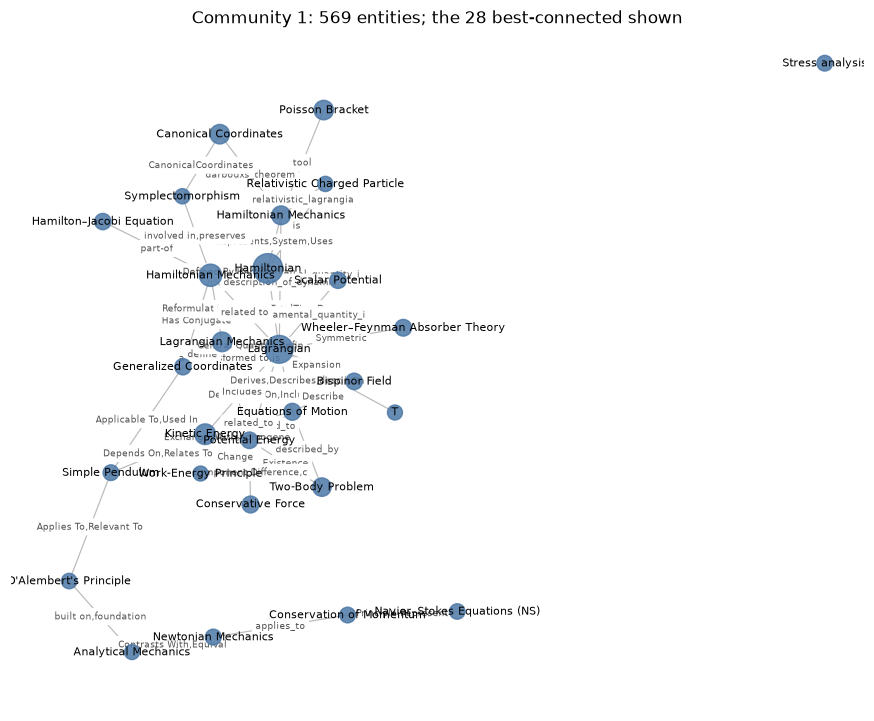

In [8]:
sizes = collections.Counter(memb)
mid = [c for c, s in sizes.most_common() if 80 <= s <= 600][0]
members = [names[i] for i in np.where(memb == mid)[0]]
top = sorted(members, key=GC.degree, reverse=True)[:28]
draw(GC.subgraph(top), f"Community {mid}: {sizes[mid]} entities; the 28 best-connected shown", seed=3)

## 2. Network-science measures

These are the standard descriptors of a complex network. For context, each is compared with an
**Erdős–Rényi (ER) random graph** with the same number of nodes and edges, where that comparison means something.

### Size, density, components
**Isolated nodes** are entities that were extracted but never linked: they can't take part in any multi-step
path. The **giant component** is the largest connected piece. Only entities inside it can reach most others.

In [9]:
degs = np.array([d for _, d in G.degree()])
comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
R.update(iso=int((degs == 0).sum()), comps=len(comps), gcc=comps[0], kmean=degs.mean())
R["iso_share"], R["gcc_share"] = R["iso"] / R["n"], R["gcc"] / R["n"]
print(f"nodes {R['n']:,}   edges {R['m']:,}   density {nx.density(G):.2e}   mean degree {degs.mean():.2f}   median {np.median(degs):.0f}")
print(f"isolated (degree 0): {R['iso']:,} ({R['iso_share']:.0%})    degree 1: {(degs == 1).sum():,} ({(degs == 1).mean():.0%})")
print(f"connected components: {len(comps):,}; giant component {comps[0]:,} ({R['gcc_share']:.0%} of all entities, "
      f"{comps[0] / (R['n'] - R['iso']):.0%} of linked ones); next largest: {comps[1:6]}")
cs = collections.Counter(min(c, 10) for c in comps if c > 1)
print("sizes of the other components (10 = 10+):", dict(sorted(cs.items())))

nodes 43,999   edges 29,551   density 3.05e-05   mean degree 1.34   median 1
isolated (degree 0): 21,447 (49%)    degree 1: 15,433 (35%)
connected components: 22,836; giant component 18,668 (42% of all entities, 83% of linked ones); next largest: [27, 20, 20, 19, 18]
sizes of the other components (10 = 10+): {2: 927, 3: 235, 4: 111, 5: 38, 6: 27, 7: 13, 8: 12, 9: 4, 10: 22}


### Degree distribution
Many real networks are **heavy-tailed**: most nodes have few links and a few hubs have very many. The
complementary CDF $P(K \ge k)$ on log–log axes shows the tail. A straight line suggests a power law
$p(k) \propto k^{-\alpha}$. $\alpha$ is estimated by maximum likelihood (Clauset, Shalizi & Newman 2009,
discrete approximation, $k_{\min}=3$). This is a description, not a test that the tail *is* a power law.

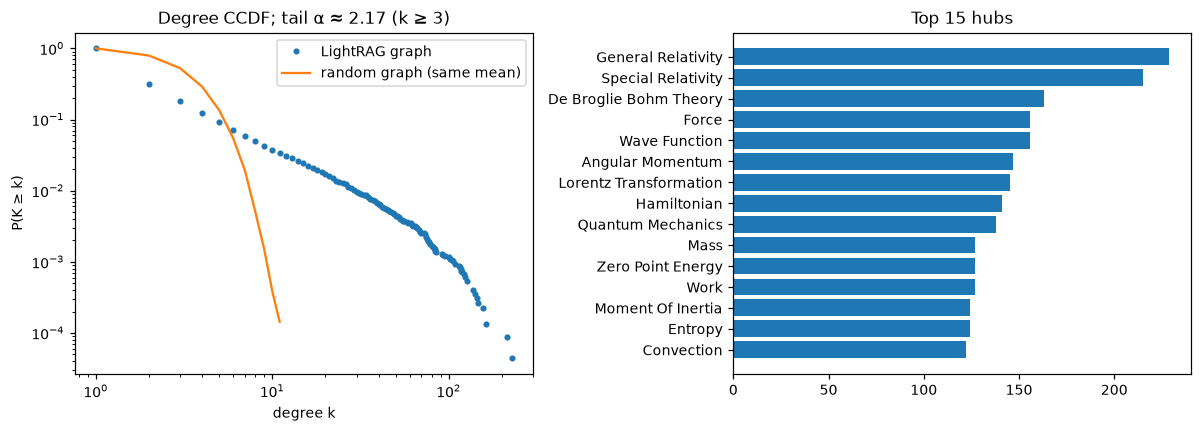

max degree 229 vs ~11 expected in a random graph of the same size


In [10]:
k = degs[degs > 0]
vals, counts = np.unique(k, return_counts=True)
ccdf = 1 - np.concatenate([[0], np.cumsum(counts)[:-1]]) / counts.sum()
kmin = 3; tail = k[k >= kmin]
alpha = 1 + len(tail) / np.log(tail / (kmin - 0.5)).sum()
R["alpha"] = alpha
er = np.random.default_rng(0).poisson(k.mean(), len(k)); er = er[er > 0]
ev, ec = np.unique(er, return_counts=True); eccdf = 1 - np.concatenate([[0], np.cumsum(ec)[:-1]]) / ec.sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(vals, ccdf, "o", ms=3, label="LightRAG graph"); ax[0].loglog(ev, eccdf, "-", label="random graph (same mean)")
ax[0].set_xlabel("degree k"); ax[0].set_ylabel("P(K ≥ k)"); ax[0].legend(); ax[0].set_title(f"Degree CCDF; tail α ≈ {alpha:.2f} (k ≥ {kmin})")
top = sorted(G.degree, key=lambda x: -x[1])[:15]
ax[1].barh([camel(n)[:28] for n, _ in top][::-1], [d for _, d in top][::-1]); ax[1].set_title("Top 15 hubs")
plt.tight_layout(); plt.show()
print(f"max degree {k.max()} vs ~{er.max()} expected in a random graph of the same size")

### Clustering and path lengths: is it a small world?
**Clustering** is the chance that two neighbours of a node are also linked to each other ("my friends are
friends"). **Average shortest path** is the typical number of hops between two entities. A **small-world**
network has clustering far above a random graph's, with paths about as short as a random graph's,
$\approx \ln n / \ln\langle k\rangle$. Paths are sampled from 300 random sources in the giant component.

giant component: n=18,668, mean degree 2.89
average clustering 0.055   global transitivity 0.025   random graph ≈ 0.00015   ratio ≈ 357×
average shortest path 5.80 hops (random ≈ 9.26);  longest sampled path 19 hops


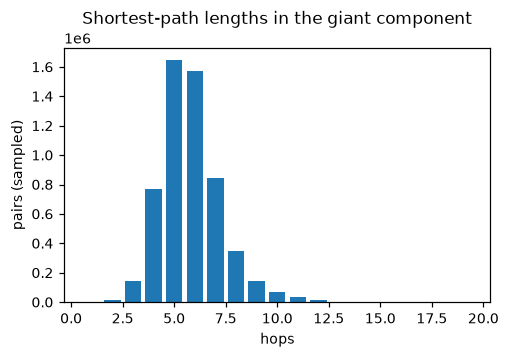

In [11]:
C_avg, C_glob = nx.average_clustering(GC), nx.transitivity(GC)
kgc = 2 * GC.number_of_edges() / GC.number_of_nodes()
C_er = kgc / GC.number_of_nodes()
rng = random.Random(0)
d = [x for s in rng.sample(names, 300) for x in nx.single_source_shortest_path_length(GC, s).values() if x > 0]
L, L_er = np.mean(d), math.log(GC.number_of_nodes()) / math.log(kgc)
R.update(C=C_avg, C_er=C_er, L=L, L_er=L_er, diam=max(d))
print(f"giant component: n={GC.number_of_nodes():,}, mean degree {kgc:.2f}")
print(f"average clustering {C_avg:.3f}   global transitivity {C_glob:.3f}   random graph ≈ {C_er:.5f}   ratio ≈ {C_avg / C_er:,.0f}×")
print(f"average shortest path {L:.2f} hops (random ≈ {L_er:.2f});  longest sampled path {max(d)} hops")
plt.figure(figsize=(5, 3)); plt.hist(d, bins=range(1, max(d) + 2), align="left", rwidth=0.8)
plt.xlabel("hops"); plt.ylabel("pairs (sampled)"); plt.title("Shortest-path lengths in the giant component"); plt.show()

### Assortativity and k-cores
**Degree assortativity** $r$ is the correlation between the degrees at the two ends of an edge. Social
networks tend to have $r>0$ (hubs link to hubs); technological and biological networks tend to have $r<0$
(hubs link to small nodes, hub-and-spoke). The **k-core** is the largest subgraph in which every node has at
least $k$ neighbours inside it. It peels away the periphery and leaves the densely interlinked backbone.

In [12]:
r = nx.degree_assortativity_coefficient(GC); R["assort"] = r
core = nx.core_number(GC); kmax = max(core.values())
cc = collections.Counter(core.values())
print(f"degree assortativity r = {r:.3f}")
print("nodes per core number:", dict(sorted(cc.items())))
inner = sorted([n for n, c in core.items() if c == kmax], key=GC.degree, reverse=True)
R["kmax"], R["kcore_n"] = kmax, len(inner)
print(f"innermost core (k={kmax}): {len(inner)} entities, e.g. {[camel(n) for n in inner[:15]]}")

degree assortativity r = -0.124
nodes per core number: {1: 13431, 2: 3050, 3: 1047, 4: 524, 5: 300, 6: 114, 7: 122, 8: 80}
innermost core (k=8): 80 entities, e.g. ['General Relativity', 'Special Relativity', 'De Broglie Bohm Theory', 'Force', 'Wave Function', 'Angular Momentum', 'Lorentz Transformation', 'Hamiltonian', 'Zero Point Energy', 'Mass', 'Work', 'Moment Of Inertia', 'Relativistic Quantum Mechanics', 'Momentum', 'Kinetic Energy']


### Centrality: which entities matter?
Different centralities answer different questions. **Degree** counts direct links. **PageRank** is the
long-run share of time a random walker spends at a node; HippoRAG uses a *personalized* version of it for
retrieval. **Betweenness** is the share of shortest paths passing through a node, i.e. the bridges between
topics (approximated from 300 sampled sources). Bridges matter for multi-step questions, because chains
between topics must cross them.

In [13]:
pr = nx.pagerank(GC)
bt = nx.betweenness_centrality(GC, k=300, seed=0)
rows = zip(sorted(GC.degree, key=lambda x: -x[1])[:12], sorted(pr.items(), key=lambda x: -x[1])[:12],
           sorted(bt.items(), key=lambda x: -x[1])[:12])
print(f"{'degree':34s}{'PageRank':34s}{'betweenness':34s}")
for (a1, b1), (a2, b2), (a3, b3) in rows:
    print(f"{camel(a1)[:26]:26s}{b1:6d}  {camel(a2)[:26]:26s}{b2:.4f}  {camel(a3)[:26]:26s}{b3:.4f}")

degree                            PageRank                          betweenness                       
General Relativity           229  Special Relativity        0.0038  Force                     0.0939
Special Relativity           215  General Relativity        0.0036  Special Relativity        0.0579
De Broglie Bohm Theory       163  Wave Function             0.0035  Quantum Mechanics         0.0576
Force                        156  De Broglie Bohm Theory    0.0029  Momentum                  0.0573
Wave Function                156  Convection                0.0024  General Relativity        0.0408
Angular Momentum             147  Hamiltonian               0.0022  Wave Function             0.0405
Lorentz Transformation       145  Force                     0.0022  Velocity                  0.0392
Hamiltonian                  141  Quantum Field Theory      0.0022  Quantum Mechanics         0.0387
Quantum Mechanics            138  Moment Of Inertia         0.0022  De Broglie Bohm Theor

### Communities
Louvain finds a partition that maximises **modularity** $Q$: how many more edges fall inside communities
than a random graph with the same degrees would give. $Q > 0.3$ is usually read as clear community structure.

In [14]:
Q = comm.modularity; R["Q"], R["ncomm"] = Q, len(sizes)
print(f"{len(sizes):,} communities, modularity Q = {Q:.3f}; largest sizes: {[s for _, s in sizes.most_common(10)]}")
for c, s in sizes.most_common(8):
    mem = sorted([names[i] for i in np.where(memb == c)[0]], key=GC.degree, reverse=True)[:8]
    print(f"  community {c} ({s}): " + ", ".join(camel(x) for x in mem))

63 communities, modularity Q = 0.794; largest sizes: [1301, 828, 816, 774, 721, 706, 698, 659, 603, 569]
  community 26 (1301): Wave Function, Quantum Mechanics, Schrödinger Equation, Einstein, Copenhagen Interpretation, Hilbert Space, Albert Einstein, Quantum Entanglement
  community 13 (828): Force, Mass, Equations Of Motion, Velocity, Acceleration, Earth, Displacement, Weight
  community 31 (816): Quantum Mechanics, Wavefunction, Schrödinger Equation, Quantum Entanglement, Dirac Equation, Bra-Ket Notation, Wave Function, Bell's Theorem
  community 3 (774): General Relativity, Concept, Gravity, White Hole, Tests Of General Relativity, Spacetime, Fictitious Force, Hawking Radiation
  community 21 (721): Stress, Hooke's Law, Material, Youngs Modulus, Solid Mechanics, Rheology, Strength Of Materials, Cauchy Stress Tensor
  community 2 (706): Special Relativity, Length Contraction, Classical Mechanics, Time Dilation, Proper Time, Isaac Newton, Pauli Equation, Lorentz Force
  community 17

### Robustness: what happens when hubs disappear?
This is a percolation experiment. Remove a growing fraction of entities, either at random or the
highest-degree ones first, and track the size of the giant component. Heavy-tailed networks are typically
robust to random failure but fragile to targeted hub removal. Here that means a few generic hub entities
hold the connected graph together.

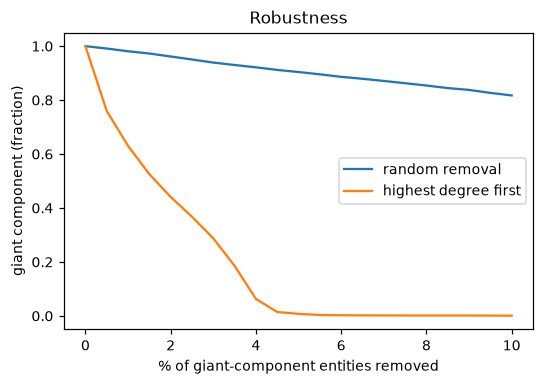

removing the top 1% of hubs (186 entities) leaves a giant component of 63%; random 1%: 98%


In [15]:
hg = ig.Graph(n=len(names), edges=[(idx[u], idx[v]) for u, v in GC.edges()])
order_t = list(np.argsort(-np.array(hg.degree())))
fr = np.linspace(0, 0.10, 21)
def gcc_after(order, f):
    g2 = hg.copy(); g2.delete_vertices(order[: int(f * len(names))])
    return max(g2.connected_components().sizes()) / len(names) if g2.vcount() else 0
targ = [gcc_after(order_t, f) for f in fr]
rand = np.mean([[gcc_after(list(np.random.default_rng(s).permutation(len(names))), f) for f in fr] for s in range(3)], axis=0)
R["gcc_after_1pct_hubs"] = targ[2]
plt.figure(figsize=(5.5, 3.5)); plt.plot(fr * 100, rand, label="random removal"); plt.plot(fr * 100, targ, label="highest degree first")
plt.xlabel("% of giant-component entities removed"); plt.ylabel("giant component (fraction)"); plt.legend(); plt.title("Robustness"); plt.show()
print(f"removing the top 1% of hubs ({int(0.01 * len(names))} entities) leaves a giant component of {targ[2]:.0%}; random 1%: {rand[2]:.0%}")

## 3. Knowledge-graph measures

KG quality is usually discussed along a few dimensions (Zaveri et al. 2016, *Quality assessment for Linked
Data*; Paulheim 2017, *Knowledge graph refinement*): **completeness** (are the facts there?), **conciseness
/ redundancy** (is each thing represented once?), **consistency** (types, names and relations used uniformly?),
**accuracy** (are the facts true and supported?), plus **provenance** (can each fact be traced to a source?).
The cells below measure the ones that can be computed without human labels.

### Types and schema
The entity types the LLM assigned, and which types the relations connect: the graph's implicit schema.

In [16]:
typ = {n: (a.get("entity_type") or "unknown").lower() for n, a in G.nodes(data=True)}
tc = collections.Counter(typ.values()); R["ntypes"] = len(tc)
print(f"{len(tc)} distinct entity types; top: {tc.most_common(12)}")
pairs = collections.Counter(tuple(sorted((typ[u], typ[v]))) for u, v in G.edges())
print("\nmost common type pairs connected by a relation:")
for (a1, b1), c in pairs.most_common(10):
    print(f"  {a1:>12s} — {b1:<12s} {c:6,d}")

200 distinct entity types; top: [('concept', 21859), ('artifact', 5792), ('unknown', 4309), ('method', 2777), ('data', 2236), ('person', 1959), ('location', 1123), ('event', 1021), ('organization', 534), ('naturalobject', 532), ('content', 486), ('creature', 240)]

most common type pairs connected by a relation:
       concept — concept      10,197
       concept — unknown       2,952
      artifact — concept       2,892
       concept — method        1,578
       concept — person        1,399
       concept — data            743
      artifact — unknown         721
      artifact — artifact        704
       concept — event           619
       concept — location        569


### Relation vocabulary
A curated KG has a small, fixed set of relations (`bornIn`, `discovered`, ...). An LLM-built graph invents
its own labels. Many distinct labels used only once mean relations can't be queried or reasoned over
consistently. Labels are drawn as a rank–frequency (Zipf) plot.

10,627 distinct relation keywords for 29,551 relations; 67% of keywords used once
top 20: [('describes', 538), ('involves', 420), ('uses', 399), ('dependson', 318), ('component', 286), ('application', 240), ('relatedto', 215), ('includes', 213), ('related_to', 198), ('causes', 191), ('concept', 162), ('dependenton', 153), ('partof', 148), ('associatedwith', 144), ('represents', 133), ('representation', 130), ('description', 128), ('definedby', 123), ('usedin', 123), ('definition', 116)]


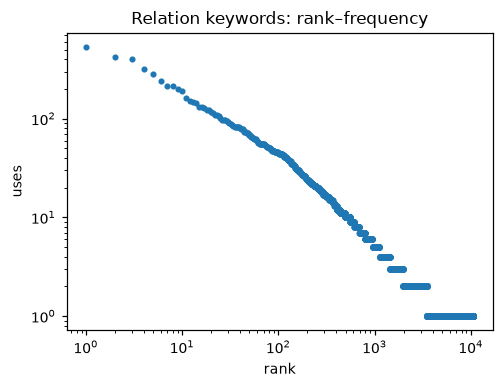

In [17]:
lab = collections.Counter(k.strip().lower() for _, _, d in G.edges(data=True) for k in (d.get("keywords") or "").split(",") if k.strip())
once = sum(1 for c in lab.values() if c == 1)
R["nrel"], R["rel_once"] = len(lab), once / len(lab)
print(f"{len(lab):,} distinct relation keywords for {R['m']:,} relations; {once / len(lab):.0%} of keywords used once")
print("top 20:", lab.most_common(20))
f = np.array(sorted(lab.values(), reverse=True))
plt.figure(figsize=(5, 3.5)); plt.loglog(np.arange(1, len(f) + 1), f, "."); plt.xlabel("rank"); plt.ylabel("uses")
plt.title("Relation keywords: rank–frequency"); plt.show()

### Provenance and extraction yield
How much each passage contributed, and how many passages support each fact. A fact found in several
passages is better attested; a passage contributing nothing is invisible to graph retrieval.

In [18]:
per_edge = np.array([len(sources(d)) for _, _, d in G.edges(data=True)])
chunks = [json.loads(l)["chunk_id"] for l in open(f"{D}/corpus/physics_v1_mech/chunks.jsonl")]
e_per_chunk = collections.Counter(c for _, _, d in G.edges(data=True) for c in sources(d))
n_per_chunk = collections.Counter(c for _, a in G.nodes(data=True) for c in sources(a))
y = np.array([e_per_chunk.get(c, 0) for c in chunks])
R["multi_src"], R["chunks_no_edge"] = (per_edge >= 2).mean(), (y == 0).mean()
print(f"relations supported by >= 2 passages: {(per_edge >= 2).mean():.1%}")
print(f"relations per passage: mean {y.mean():.1f}, median {np.median(y):.0f}; passages with no relation: {(y == 0).mean():.1%}; "
      f"passages with no entity: {np.mean([n_per_chunk.get(c, 0) == 0 for c in chunks]):.1%}")
print(f"entities per passage: mean {np.mean([n_per_chunk.get(c, 0) for c in chunks]):.1f}")

relations supported by >= 2 passages: 3.5%
relations per passage: mean 10.6, median 9; passages with no relation: 1.3%; passages with no entity: 0.0%
entities per passage: mean 22.8


### Redundancy and naming consistency
The same thing extracted under several names splits its facts across nodes. That breaks paths and inflates
the entity count. Measured here: names that collide after normalisation (case, CamelCase, punctuation, plural),
the share of run-together CamelCase names, and how often an entity was re-extracted and merged.

In [19]:
groups = collections.defaultdict(list)
for n in G:
    nn = NORM[n]; groups[nn[:-1] if nn.endswith("s") and len(nn) > 3 else nn].append(n)
dups = {k: v for k, v in groups.items() if len(v) > 1}
camel_share = np.mean([bool(re.search(r"[a-z][A-Z]", n)) and " " not in n for n in G])
merged = np.array([len((a.get("description") or "").split(SEP)) for _, a in G.nodes(data=True)])
R["dup_share"], R["camel"] = sum(len(v) for v in dups.values()) / R["n"], camel_share
print(f"entities sharing a normalised name with another: {R['dup_share']:.1%} ({len(dups):,} groups)")
print("examples:", [v[:4] for v in sorted(dups.values(), key=len, reverse=True)[:6]])
print(f"CamelCase run-together names: {camel_share:.0%}")
print(f"descriptions merged per entity: mean {merged.mean():.2f}; extracted from >= 2 passages: {(merged >= 2).mean():.0%}")

entities sharing a normalised name with another: 26.3% (4,649 groups)
examples: [['EulerLagrangeEquation', 'EulerLagrangeEquations', 'Euler–Lagrange equations', 'Euler–LagrangeEquations'], ['ShockWave', 'Shock_wave', 'Shock_Waves', 'ShockWaves'], ['PositionVector', 'positionVector', 'Position vector', 'Position_vector'], ['ExternalForce', 'External Force', 'External Forces', 'external_forces'], ['WaveFunction', 'Wave Function', 'wave_function', 'WaveFunctions'], ['InertialForces', 'InertialForce', 'Inertial Force', 'Inertial Forces']]
CamelCase run-together names: 52%
descriptions merged per entity: mean 1.28; extracted from >= 2 passages: 14%


### Completeness (proxy): are the answers in the graph?
For the eval set's answerable questions: is the gold answer an entity in the graph (after normalisation)? If
it isn't, a graph-only system can't return it. It would have to fall back on source text.

In [20]:
ev = [json.loads(l) for l in open(f"{D}/eval/physics_v1_mech/eval_v1.jsonl")]
names_norm = set(NORM.values())
cov = collections.defaultdict(list)
for q in ev:
    if q["type"] != "unanswerable":
        cov[q["type"]].append(norm(q["answer"]) in names_norm)
for t, v in cov.items():
    print(f"{t:9s} gold answer present as an entity: {np.mean(v):.0%} (n={len(v)})")
R["cov"] = {t: np.mean(v) for t, v in cov.items()}

single    gold answer present as an entity: 56% (n=70)
multihop  gold answer present as an entity: 28% (n=39)


### Comparison: HippoRAG's graph from the same passages
HippoRAG builds a different kind of graph from the same passages with the same 7B model: open
information-extraction triples, without descriptions or types. Here are the same basic measures on its
triple graph. (HippoRAG also adds passage nodes and 'synonym' edges for retrieval, which are not facts, so
they are left out.)

In [21]:
docs = json.load(open(f"{D}/graphs/hipporag_main/openie_results_ner_qwen2.5-7b.json"))["docs"]
H = nx.Graph(); hrel = collections.Counter()
for d in docs:
    for t in d.get("extracted_triples", []):
        if len(t) == 3 and all(isinstance(x, str) and x.strip() for x in t) and t[0].strip() != t[2].strip():
            H.add_edge(t[0].strip(), t[2].strip()); hrel[t[1].strip().lower()] += 1
for d in docs:
    H.add_nodes_from(e.strip() for e in d.get("extracted_entities", []) if isinstance(e, str) and e.strip())
def summary(X, nrel):
    dg = np.array([d for _, d in X.degree()]); comps_ = sorted((len(c) for c in nx.connected_components(X)), reverse=True)
    gx = X.subgraph(max(nx.connected_components(X), key=len))
    return [f"{X.number_of_nodes():,}", f"{X.number_of_edges():,}", f"{dg.mean():.2f}", f"{(dg == 0).mean():.0%}",
            f"{comps_[0] / X.number_of_nodes():.0%}", f"{nx.transitivity(gx):.3f}", f"{nrel:,}"]
rows = ["entities", "relations (unique pairs)", "mean degree", "isolated", "giant component", "transitivity (giant)", "distinct relation labels"]
for r_, a1, b1 in zip(rows, summary(G, len(lab)), summary(H, len(hrel))):
    print(f"{r_:26s} {a1:>12s} {b1:>12s}")
print(f"{'':26s} {'LightRAG':>12s} {'HippoRAG':>12s}")

entities                         43,999       60,888
relations (unique pairs)         29,551       50,851
mean degree                        1.34         1.67
isolated                            49%          15%
giant component                     42%          53%
transitivity (giant)              0.025        0.006
distinct relation labels         10,627       13,782
                               LightRAG     HippoRAG


### Standard KG measures not computed here
- **Link prediction** (MRR, Hits@k): train a KG embedding (TransE, RotatE, ...) on most edges and test whether
  it ranks held-out edges highly. This is the standard benchmark for completion methods, but it measures how
  *predictable* the graph is, not whether it is true. It needs GPU training.
- **Fact accuracy / precision:** sample facts and check them against the source passage, by a person or an
  entailment model. It is the most important quality measure for QA, and the obvious next step: provenance
  is already stored on every edge.
- **Schema conformance:** checking facts against an ontology (e.g. SHACL constraints). An LLM-built graph like
  this has no fixed ontology to check against.

## 4. Takeaways (computed from the numbers above)

In [22]:
display(Markdown(f'''
- **Big but sparse.** {R["n"]:,} entities and {R["m"]:,} relations, a mean degree of {R["kmean"]:.2f}.
  **{R["iso_share"]:.0%} of entities have no links at all**, and the giant component holds {R["gcc_share"]:.0%}
  of entities. The 7B model names things far more readily than it connects them.
- **Heavy-tailed, with generic hubs.** The degree tail exponent is α ≈ {R["alpha"]:.2f}. Removing just the top 1%
  of hubs shrinks the giant component to {R["gcc_after_1pct_hubs"]:.0%}, so a handful of generic entities hold
  the connected part together.
- **Small-world inside the giant component.** Clustering is {R["C"]:.3f}, about {R["C"] / R["C_er"]:,.0f}× a random
  graph's, and paths average {R["L"]:.1f} hops (random ≈ {R["L_er"]:.1f}). Degree assortativity is r = {R["assort"]:.2f},
  and modularity is Q = {R["Q"]:.2f} over {R["ncomm"]:,} communities, i.e. topical clusters.
- **No consistent relation vocabulary.** {R["nrel"]:,} distinct relation keywords, {R["rel_once"]:.0%} used only once.
  The relations can't be queried as a schema; they work only as free text.
- **Redundant, inconsistent names.** {R["camel"]:.0%} of names are run-together CamelCase, and
  {R["dup_share"]:.1%} of entities collide with another after simple normalisation.
- **Thin provenance.** Only {R["multi_src"]:.0%} of relations are supported by more than one passage, and
  {R["chunks_no_edge"]:.0%} of passages contributed no relation at all.
- **Completeness.** The gold answer exists as an entity for {R["cov"].get("single", 0):.0%} of single-fact and
  {R["cov"].get("multihop", 0):.0%} of two-step questions. Elsewhere, graph-only retrieval cannot produce the answer.
'''))


- **Big but sparse.** 43,999 entities and 29,551 relations, a mean degree of 1.34.
  **49% of entities have no links at all**, and the giant component holds 42%
  of entities. The 7B model names things far more readily than it connects them.
- **Heavy-tailed, with generic hubs.** The degree tail exponent is α ≈ 2.17. Removing just the top 1%
  of hubs shrinks the giant component to 63%, so a handful of generic entities hold
  the connected part together.
- **Small-world inside the giant component.** Clustering is 0.055, about 357× a random
  graph's, and paths average 5.8 hops (random ≈ 9.3). Degree assortativity is r = -0.12,
  and modularity is Q = 0.79 over 63 communities, i.e. topical clusters.
- **No consistent relation vocabulary.** 10,627 distinct relation keywords, 67% used only once.
  The relations can't be queried as a schema; they work only as free text.
- **Redundant, inconsistent names.** 52% of names are run-together CamelCase, and
  26.3% of entities collide with another after simple normalisation.
- **Thin provenance.** Only 3% of relations are supported by more than one passage, and
  1% of passages contributed no relation at all.
- **Completeness.** The gold answer exists as an entity for 56% of single-fact and
  28% of two-step questions. Elsewhere, graph-only retrieval cannot produce the answer.
